In [13]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import Hao_Harris_A1 as h


N, C = 256, 128                                   

COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
def make_square(side):
    img = np.zeros((N, N))
    img[C - side // 2:C + side // 2, C - side // 2:C + side // 2] = 255
    return img


def log_at_center(img, sigmas):
    return np.array([h.log_normalized(img, s)[C, C] for s in sigmas])


Tương ứng với một ảnh có nhiều layer đc xắp xếp theo $\sigma$ tăng dần thi tồn tại một điểm là $|LoG|$ Cực đại

Tháp σ: [ 1.2  1.4  1.7  2.1  2.5  3.   3.6  4.3  5.2  6.2  7.4  8.9 10.7 12.8
 15.4 18.5 22.2 26.6 31.9]


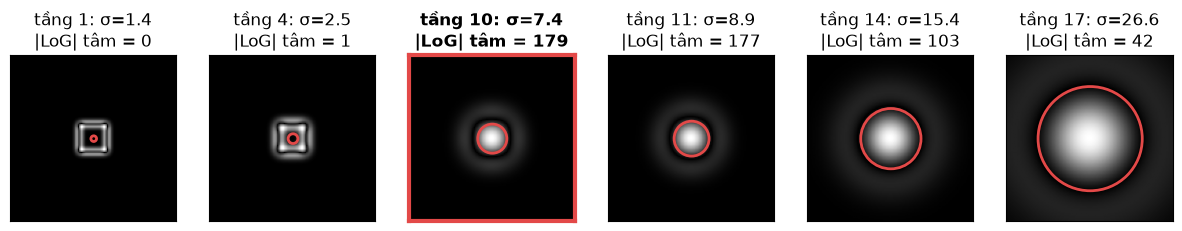

In [14]:
SIGMAS = h.scale_pyramid(sigma0=1.2, xi=1.2, n_levels=18)
print('Tháp σ:', np.round(SIGMAS, 1))

demo = make_square(20)
demo_vals = log_at_center(demo, SIGMAS)
best = int(np.argmax(demo_vals))

fig, axes = plt.subplots(1, 6, figsize=(15, 3.2))
for ax, n in zip(axes, [1, 4, best, 11, 14, 17]):
    ax.imshow(h.log_normalized(demo, SIGMAS[n])[C - 60:C + 60, C - 60:C + 60], cmap='gray')
    ax.add_patch(plt.Circle((60, 60), SIGMAS[n] * np.sqrt(2), fill=False, color='#e34948', lw=2))
    ax.set_title(f'tầng {n}: σ={SIGMAS[n]:.1f}\n|LoG| tâm = {demo_vals[n]:.0f}',
                 fontweight='bold' if n == best else 'normal')
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if n == best:
        for s in ax.spines.values():
            s.set_visible(True); s.set_color('#e34948'); s.set_linewidth(3)
plt.show()

- Theo bạn có thể thấy nếu vật càng to thì giá trị của $\sigma$ để cho $LoG$ cực đại tương ứng thì có giá trị lớn hơn

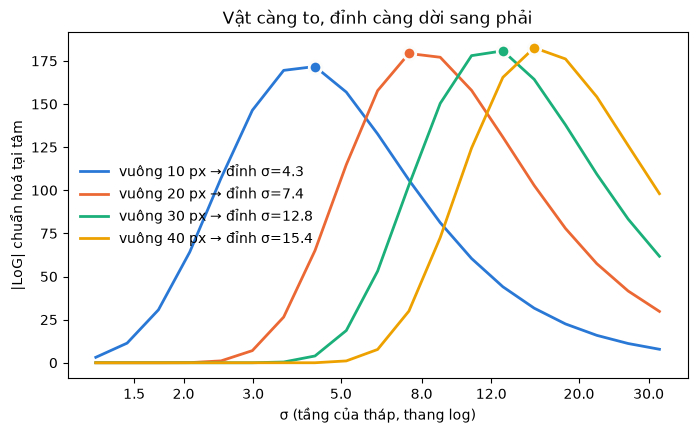

In [15]:
SIZES = [10, 20, 30, 40]
best_sigma = []

fig, ax = plt.subplots(figsize=(8, 4.5))
for side, color in zip(SIZES, COLORS):
    vals = log_at_center(make_square(side), SIGMAS)
    b = int(np.argmax(vals))
    best_sigma.append(SIGMAS[b])
    ax.plot(SIGMAS, vals, color=color, lw=2, label=f'vuông {side} px → đỉnh σ={SIGMAS[b]:.1f}')
    ax.plot(SIGMAS[b], vals[b], 'o', ms=9, color=color, mec='#fcfcfb', mew=2)
ax.set_xscale('log'); ax.set_xticks([1.5, 2, 3, 5, 8, 12, 20, 30])
ax.xaxis.set_major_formatter(plt.ScalarFormatter()); ax.minorticks_off()
ax.set_xlabel('σ (tầng của tháp, thang log)'); ax.set_ylabel('|LoG| chuẩn hoá tại tâm')
ax.set_title('Vật càng to, đỉnh càng dời sang phải'); ax.legend(frameon=False)
plt.show()

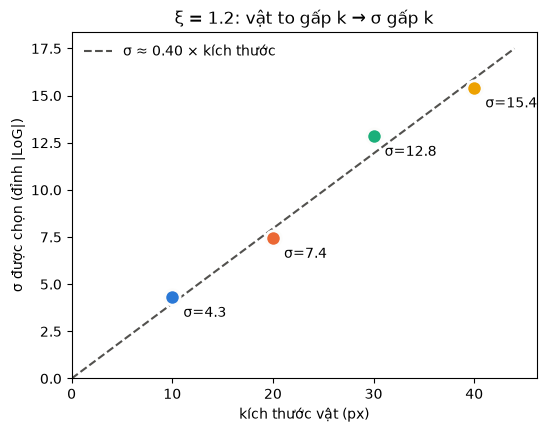

np.float64(0.3976854153619044)

In [16]:
def plot_size_vs_sigma(sizes, best_sigma, title):
    """Chấm (kích thước, σ đỉnh) và đường thẳng qua gốc σ = a·kích thước (bình phương tối thiểu)."""
    sizes, best_sigma = np.array(sizes), np.array(best_sigma)
    a = np.sum(sizes * best_sigma) / np.sum(sizes ** 2)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    xs = np.linspace(0, sizes.max() * 1.1, 10)
    ax.plot(xs, a * xs, '--', color='#52514e', lw=1.5, label=f'σ ≈ {a:.2f} × kích thước')
    for side, sig, color in zip(sizes, best_sigma, COLORS):
        ax.plot(side, sig, 'o', ms=11, color=color, mec='#fcfcfb', mew=2)
        ax.annotate(f'σ={sig:.1f}', (side, sig), textcoords='offset points', xytext=(8, -14))
    ax.set_xlim(0, None); ax.set_ylim(0, None)
    ax.set_xlabel('kích thước vật (px)'); ax.set_ylabel('σ được chọn (đỉnh |LoG|)')
    ax.set_title(title); ax.legend(frameon=False, loc='upper left')
    plt.show()
    return a

plot_size_vs_sigma(SIZES, best_sigma, 'ξ = 1.2: vật to gấp k → σ gấp k')


ξ=1.2: 19 tầng, σ đỉnh = [ 4.3  7.4 12.8 15.4]


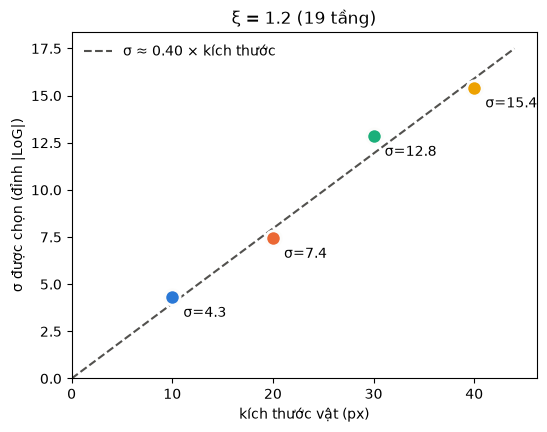

ξ=2.0: 6 tầng, σ đỉnh = [ 4.8  9.6  9.6 19.2]


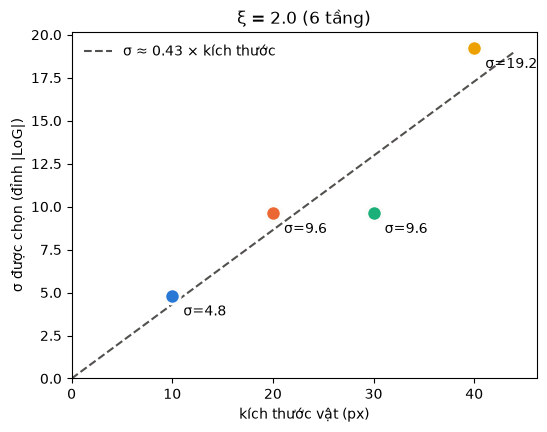

In [17]:
for xi in [1.2, 2.0]:
    n_levels = int(np.ceil(np.log(30 / 1.2) / np.log(xi)))      # luôn phủ σ từ 1.2 tới ~30
    sig = h.scale_pyramid(1.2, xi, n_levels)
    bs = [sig[int(np.argmax(log_at_center(make_square(s), sig)))] for s in SIZES]
    print(f'ξ={xi}: {len(sig)} tầng, σ đỉnh = {np.round(bs, 1)}')
    plot_size_vs_sigma(SIZES, bs, f'ξ = {xi} ({len(sig)} tầng)')

In [18]:
SIZE_A, N_KEEP, XI = 120, 100, 1.4
SCALES = [1.0, 1.5, 2.0, 2.5, 3.0]
# dải ×8 trong A, nhân thêm hệ số phóng lớn nhất; +1 vì tầng cuối bị bỏ (thiếu hàng xóm)
SIGMAS_HL = h.scale_pyramid(1.2, XI, int(np.ceil(np.log(8 * max(SCALES)) / np.log(XI))) + 1)


def top_n_by_response(points, n):
    """Giữ n điểm có response (cột cuối) lớn nhất."""
    return points[np.argsort(-points[:, -1])][:n]


def repeat_after_scaling(grey, scale):
    """Repeatability (classic, Harris-Laplace) khi ảnh bị phóng `scale` lần."""
    a = cv.resize(grey, (SIZE_A, SIZE_A), interpolation=cv.INTER_AREA)
    b = cv.resize(a, None, fx=scale, fy=scale, interpolation=cv.INTER_CUBIC)
    t = 0.5 * (scale - 1)                                        # cv.resize căn theo tâm pixel
    S = np.array([[scale, 0, t], [0, scale, t]])                 # A (x, y) -> B (x, y)
    rep_classic = h.repeatability(top_n_by_response(h.harris_classic(a), N_KEEP),
                                  top_n_by_response(h.harris_classic(b), N_KEEP), S, b.shape)
    rep_hl = h.repeatability(top_n_by_response(h.harris_laplace(a, SIGMAS_HL), N_KEEP),
                             top_n_by_response(h.harris_laplace(b, SIGMAS_HL), N_KEEP), S, b.shape)
    return rep_classic, rep_hl


results = {}
for name in ['chess.jpg', 'flowers.jpg']:
    grey = h.convert2grey(cv.imread(name))
    results[name] = np.array([repeat_after_scaling(grey, s) for s in SCALES])
    print(name); print('  scale   classic   Harris-Laplace')
    for s, (rc, rh) in zip(SCALES, results[name]):
        print(f'  {s:4.1f}    {rc:6.3f}    {rh:6.3f}')

chess.jpg
  scale   classic   Harris-Laplace
   1.0     1.000     1.000
   1.5     0.860     0.810
   2.0     0.750     0.820
   2.5     0.520     0.760
   3.0     0.360     0.530
flowers.jpg
  scale   classic   Harris-Laplace
   1.0     1.000     1.000
   1.5     0.510     0.640
   2.0     0.280     0.540
   2.5     0.110     0.410
   3.0     0.080     0.360


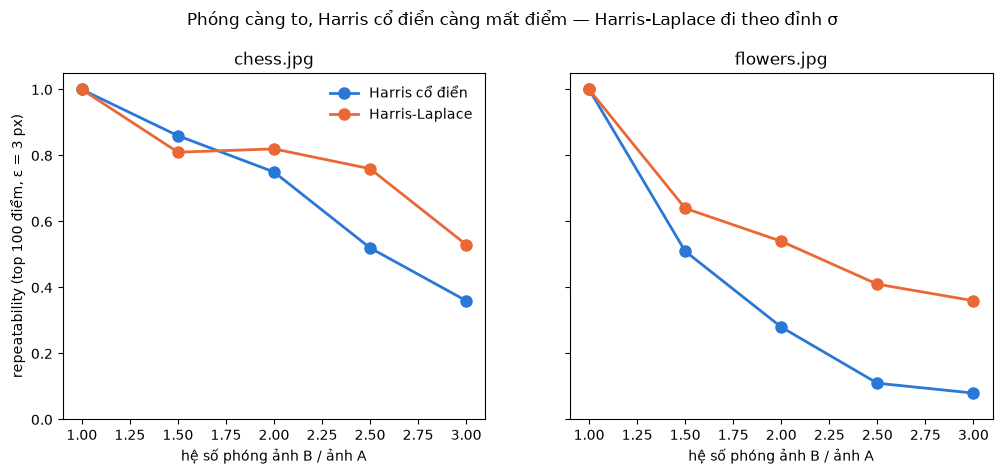

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    ax.plot(SCALES, r[:, 0], 'o-', color=COLORS[0], lw=2, ms=8, label='Harris cổ điển')
    ax.plot(SCALES, r[:, 1], 'o-', color=COLORS[1], lw=2, ms=8, label='Harris-Laplace')
    ax.set_title(name); ax.set_xlabel('hệ số phóng ảnh B / ảnh A'); ax.set_ylim(0, 1.05)
axes[0].set_ylabel(f'repeatability (top {N_KEEP} điểm, ε = 3 px)')
axes[0].legend(frameon=False)
fig.suptitle('Phóng càng to, Harris cổ điển càng mất điểm — Harris-Laplace đi theo đỉnh σ', y=1.02)
plt.show()


chess.jpg
  góc    classic   Harris-Laplace
    0°     1.000     1.000
   15°     0.940     0.950
   30°     0.938     0.946
   45°     0.927     0.902
   60°     0.927     0.957
   75°     0.980     0.940
   90°     1.000     1.000
flowers.jpg
  góc    classic   Harris-Laplace
    0°     0.920     0.910
   15°     0.943     0.928
   30°     0.919     0.939
   45°     0.894     0.835
   60°     0.895     0.875
   75°     0.902     0.848
   90°     0.920     0.910


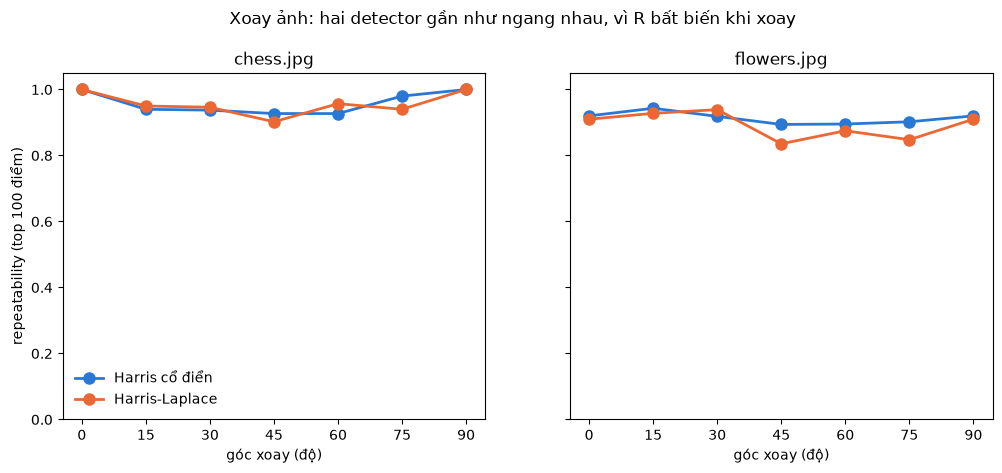

In [20]:
ANGLES = [0, 15, 30, 45, 60, 75, 90]
SIZE_ROT = 240   # lớn hơn SIZE_A để nội suy khi xoay ít làm méo góc


def drop_points_from_black_corners(points, M_inv, shape_a, margin=5):
    """Bỏ điểm q của B nếu T⁻¹(q) = M_inv · [x, y, 1]ᵀ rơi ra ngoài A (vùng đen do xoay)."""
    xy1 = np.column_stack((points[:, 1], points[:, 0], np.ones(len(points))))   # (row, col) -> (x, y, 1)
    x, y = (xy1 @ M_inv.T).T
    H, W = shape_a
    keep = (x >= margin) & (x < W - margin) & (y >= margin) & (y < H - margin)
    return points[keep]


def repeat_after_rotation(grey, angle):
    """Repeatability (classic, Harris-Laplace) khi ảnh bị xoay `angle` độ quanh tâm."""
    a = cv.resize(grey, (SIZE_ROT, SIZE_ROT), interpolation=cv.INTER_AREA)
    center = ((SIZE_ROT - 1) / 2, (SIZE_ROT - 1) / 2)          # tâm pixel thật -> 90° là hoán vị chính xác
    M = cv.getRotationMatrix2D(center, angle, 1.0)             # A (x, y) -> B (x, y)
    b = cv.warpAffine(a, M, (SIZE_ROT, SIZE_ROT), flags=cv.INTER_CUBIC)
    M_inv = cv.invertAffineTransform(M)

    reps = []
    for detect in (h.harris_classic, lambda img: h.harris_laplace(img, SIGMAS_HL)):
        pts_a = top_n_by_response(detect(a), N_KEEP)
        pts_b = top_n_by_response(drop_points_from_black_corners(detect(b), M_inv, a.shape), N_KEEP)
        reps.append(h.repeatability(pts_a, pts_b, M, b.shape))
    return reps


rot_results = {}
for name in ['chess.jpg', 'flowers.jpg']:
    grey = h.convert2grey(cv.imread(name))
    rot_results[name] = np.array([repeat_after_rotation(grey, ang) for ang in ANGLES])
    print(name); print('  góc    classic   Harris-Laplace')
    for ang, (rc, rh) in zip(ANGLES, rot_results[name]):
        print(f'  {ang:3d}°    {rc:6.3f}    {rh:6.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, r) in zip(axes, rot_results.items()):
    ax.plot(ANGLES, r[:, 0], 'o-', color=COLORS[0], lw=2, ms=8, label='Harris cổ điển')
    ax.plot(ANGLES, r[:, 1], 'o-', color=COLORS[1], lw=2, ms=8, label='Harris-Laplace')
    ax.set_title(name); ax.set_xlabel('góc xoay (độ)'); ax.set_ylim(0, 1.05); ax.set_xticks(ANGLES)
axes[0].set_ylabel(f'repeatability (top {N_KEEP} điểm)')
axes[0].legend(frameon=False)
fig.suptitle('Xoay ảnh: hai detector gần như ngang nhau, vì R bất biến khi xoay', y=1.02)
plt.show()

207 điểm ở A, 84 điểm ở B, chọn 1 cặp: [(np.float64(6.19), np.float64(12.84))]


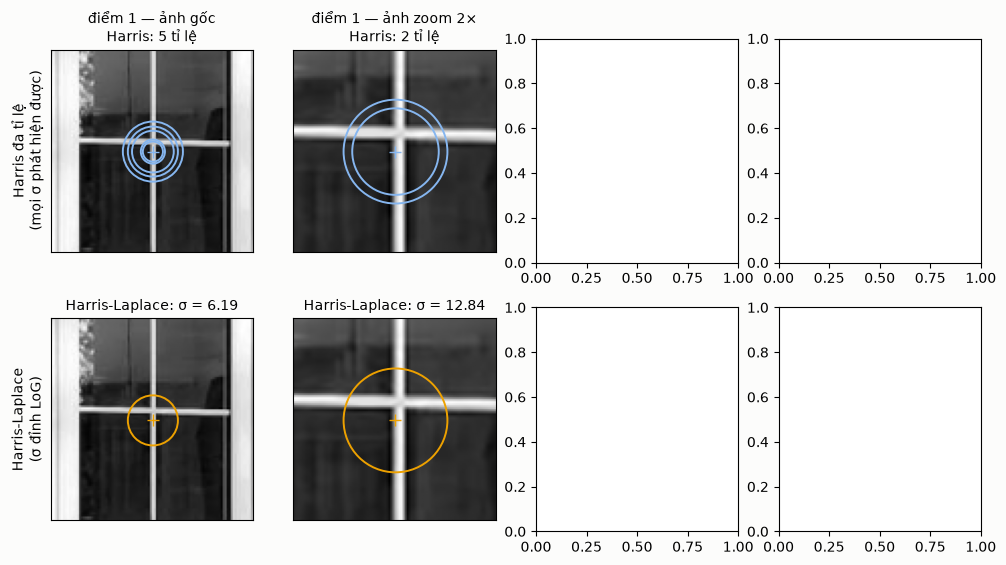

In [21]:
SIZE, ZOOM, CROP =  320, 2.0, 100     # ảnh, cỡ ảnh A, hệ số zoom, cỡ ô cắt
RADIUS_PER_SIGMA = 2.0                                   # bán kính vòng = 2σ (chỉ để hiển thị)
MIN_SIGMA = 3.0
SIGMAS = h.scale_pyramid(1.2, 1.2, 14)
img =  cv.imread('window2.jpg')
grey = h.convert2grey(img)

def zoom_in(img, z):
    n = img.shape[0]
    side = int(round(n / z)); off = (n - side) // 2
    return cv.resize(img[off:off + side, off:off + side], (n, n), interpolation=cv.INTER_CUBIC), off


def harris_scales_at(img, y, x, tol=2):
    """Các σ trong tháp mà Harris (σ_I=σ, σ_D=0.7σ) có cực đại địa phương trong bán kính tol quanh (y, x)."""
    found = []
    for s in SIGMAS:
        R = h.harris_response(img, s, 0.7 * s)
        mask = h.nms_2d(R) & (R > 0.01 * R.max())
        ys, xs = np.nonzero(mask)
        if np.any(np.hypot(ys - y, xs - x) <= tol):
            found.append(s)
    return found


def matched_pairs(pa, pb, off):
    """Cặp điểm Harris-Laplace (A, B) cùng vị trí sau zoom và có σ_B/σ_A gần ZOOM nhất."""
    pairs = []
    for y, x, s, r in pa:
        if s < MIN_SIGMA:
            continue
        yb, xb = ZOOM * (y - off), ZOOM * (x - off)
        inside = CROP // 2 <= min(yb, xb) and max(yb, xb) < SIZE - CROP // 2 and \
                 CROP // 2 <= min(y, x) and max(y, x) < SIZE - CROP // 2
        if not inside:
            continue
        near = pb[np.hypot(pb[:, 0] - yb, pb[:, 1] - xb) <= 3]
        if len(near):
            best = near[np.argmin(np.abs(np.log(near[:, 2] / (ZOOM * s))))]
            pairs.append((abs(np.log(best[2] / s / ZOOM)), -r, (y, x, s), tuple(best[:3])))
    pairs.sort()
    chosen = []
    for _, _, a, b in pairs:                              # giữ các cặp cách nhau >= 20 px để không trùng
        if all(np.hypot(a[0] - c[0], a[1] - c[1]) >= 20 for c, _ in chosen):
            chosen.append((a, b))
    return chosen


def crop(img, y, x):
    """Ô vuông CROP x CROP quanh (y, x)."""
    y, x = int(y), int(x)
    return img[y - CROP // 2:y + CROP // 2, x - CROP // 2:x + CROP // 2]


def draw(ax, img, y, x, scales, color):
    """Vẽ ô cắt quanh (y, x) và một vòng tròn bán kính 2σ cho mỗi σ."""
    ax.imshow(crop(img, y, x), cmap='gray')
    for s in scales:
        ax.add_patch(plt.Circle((CROP // 2, CROP // 2), RADIUS_PER_SIGMA * s, fill=False, color=color, lw=1.4))
    ax.plot(CROP // 2, CROP // 2, '+', color=color, ms=8)
    ax.set_xticks([]); ax.set_yticks([])


A = cv.resize(grey, (SIZE, SIZE), interpolation=cv.INTER_AREA)
B, off = zoom_in(A, ZOOM)
pa, pb = h.harris_laplace(A, SIGMAS), h.harris_laplace(B, SIGMAS)
pairs = matched_pairs(pa, pb, off)[:2]
print(f'{len(pa)} điểm ở A, {len(pb)} điểm ở B, chọn {len(pairs)} cặp:',
      [(round(a[2], 2), round(b[2], 2)) for a, b in pairs])

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4), facecolor='#fcfcfb')
for k, ((ya, xa, sa), (yb, xb, sb)) in enumerate(pairs):
    for col, (img, y, x, s_hl, tag) in enumerate([(A, ya, xa, sa, 'gốc'), (B, yb, xb, sb, f'zoom {ZOOM:g}×')]):
        c = 2 * k + col
        all_s = harris_scales_at(img, y, x)
        draw(axes[0, c], img, y, x, all_s, '#86b6ef')
        draw(axes[1, c], img, y, x, [s_hl], '#eda100')
        axes[0, c].set_title(f'điểm {k + 1} — ảnh {tag}\nHarris: {len(all_s)} tỉ lệ', fontsize=10)
        axes[1, c].set_title(f'Harris-Laplace: σ = {s_hl:.2f}', fontsize=10)
axes[0, 0].set_ylabel('Harris đa tỉ lệ\n(mọi σ phát hiện được)')
axes[1, 0].set_ylabel('Harris-Laplace\n(σ đỉnh LoG)')
plt.show()

